In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
# from tqdm import tqdm
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [7]:
# import clickhouse_connect
# DATABASE_NAME = 'binance_data_indicator' 
# # OHLC_1M = 'trx_1m_ohlc'  # Changed from btc to trx
# # # INDICATOR_1M = 'trx_1m_indicator'  # Changed from btc to trx

# TABLE1_NAME = 'btcusdt_1m_extended'  # Changed table's name
# TABLE2_NAME = 'btcusdt_1m_forward_ohlc'  # Changed table's name

# # CLICKHOUSE_HOST = 'localhost' # Get qua Docker
# CLICKHOUSE_HOST = '117.0.34.78'
# CLICKHOUSE_PORT = 8123
# CLICKHOUSE_USER = 'looker'
# CLICKHOUSE_PASSWORD = ''

# clickhouse_client = clickhouse_connect.get_client(host=CLICKHOUSE_HOST, port=CLICKHOUSE_PORT, username=CLICKHOUSE_USER, password=CLICKHOUSE_PASSWORD)

# # sql = f'''
# #     SELECT * FROM {DATABASE_NAME}.{INDICATOR_1M} FINAL
# #     WHERE OpenTime >= '2024-12-01 00:00:00'
# #     ORDER BY OpenTime DESC
# #     LIMIT 400000
# # '''

# sql = f'''
#     SELECT
#     a.OpenTime,
#     a.MinuteId AS MinuteId,
#     a.Close AS Close,
#     a.* EXCEPT(OpenTime, Close, MinuteId),
#     b.* EXCEPT(OpenTime, Close, MinuteId, StartCumulative)
#     FROM
#     (SELECT * FROM {DATABASE_NAME}.{TABLE1_NAME} FINAL) AS a
#     JOIN
#     (SELECT * FROM {DATABASE_NAME}.{TABLE2_NAME} FINAL) AS b
#     ON
#     a.OpenTime = b.OpenTime
#     WHERE
#     a.Valid = '1'
#     ORDER BY
#     a.OpenTime ASC
#     LIMIT 400000
# '''
# # Đọc dữ liệu
# df = clickhouse_client.query_df(sql)

# # Chuyển đổi OpenTime thành datetime
# df['OpenTime'] = pd.to_datetime(df['OpenTime'])

# df.set_index('OpenTime', inplace=True)

# # df[['Close','Low','High','min_low_5', 'min_low_10', 'max_high_5', 'max_high_10', 'min_low_30', 'max_high_30','close_vs_minlow5_pct', 'close_vs_minlow10_pct', 'close_vs_minlow30_pct']].head(30)
# # df[['OpenTime', 'macd_diff', 'sma_macd_diff_5','sma_macd_diff_10','sma_macd_diff_sub']].head(20)

In [114]:
# Đọc dữ liệu
df = pd.read_csv('home/')
# Chuyển đổi OpenTime thành datetime
df['OpenTime'] = pd.to_datetime(df['OpenTime'])

df.set_index('OpenTime', inplace=True)
# df.sort_index(ascending=True, inplace=True)

# df[['Close','Low','High','min_low5', 'min_low10', 'max_high5', 'max_high10', 'min_low30', 'max_high30','close_vs_minlow5_pct', 'close_vs_minlow10_pct', 'close_vs_minlow30_pct']].head(30)
# df[['MACD_diff', 'SMA_MACD_diff_5','SMA_MACD_diff_10','SMA_MACD_diff_sub']].head(20)

In [115]:
Y_TYPE = 'close_vs_minlow5'

# Đếm số lượng bản ghi
count_rows = len(df)

# Đếm số lượng 0
count_zeros = (df[Y_TYPE] == 0).sum().sum()

# Đếm số lượng 1
count_ones = (df[Y_TYPE] == 1).sum().sum()

# In kết quả
print("Số lượng giá trị 0:", count_zeros)
print("Số lượng giá trị 1:", count_ones)
print("Số lượng bản ghi:", count_rows) 

Số lượng giá trị 0: 158551
Số lượng giá trị 1: 79235
Số lượng bản ghi: 237786


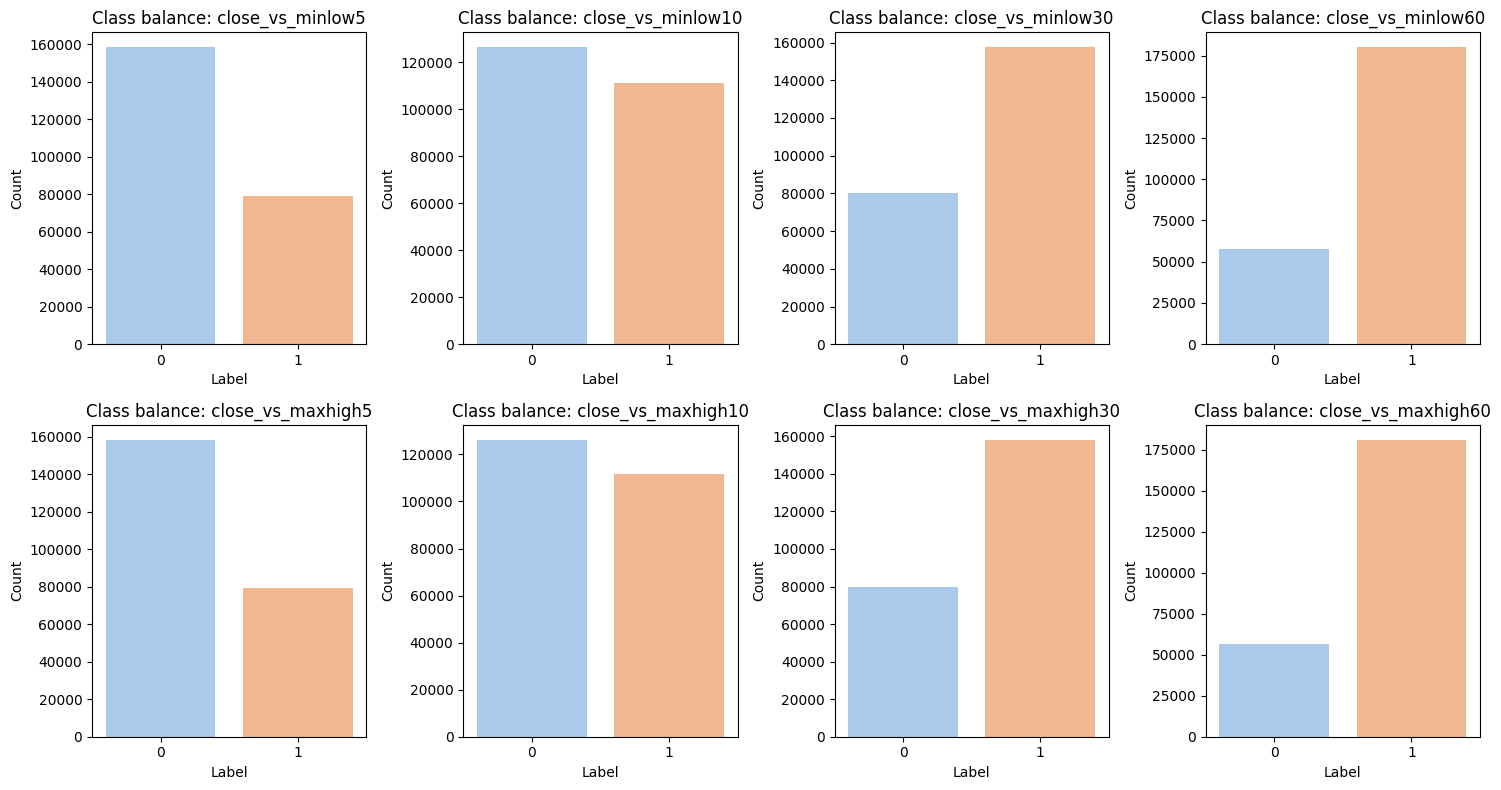

In [116]:
label_cols = [
    'close_vs_minlow5',
    'close_vs_minlow10',
    'close_vs_minlow30',
    'close_vs_minlow60',
    'close_vs_maxhigh5',
    'close_vs_maxhigh10',
    'close_vs_maxhigh30',
    'close_vs_maxhigh60',
]

# Điều chỉnh kích thước figure 
plt.figure(figsize=(15, 8))

for i, col in enumerate(label_cols):
    plt.subplot(2, 4, i + 1)  
    sns.countplot(data=df, x=col, hue=col, palette='pastel', legend=False)
    plt.title(f'Class balance: {col}')
    plt.xlabel('Label')
    plt.ylabel('Count')

plt.tight_layout()
plt.show()


In [117]:
df.isna().sum()

Close                     0
EMA_9                     0
EMA_25                    0
EMA_50                    0
SMA_9                     0
SMA_25                    0
SMA_50                    0
RSI                       0
MACD                      0
MACD_signal               0
MACD_diff                 0
High                      0
Low                       0
min_low5                  0
max_high5                 0
min_low10                 0
max_high10                0
min_low30                 0
max_high30                0
min_low60                 0
max_high60                0
close_vs_minlow5_pct      0
close_vs_minlow10_pct     0
close_vs_minlow30_pct     0
close_vs_minlow60_pct     0
close_vs_maxhigh5_pct     0
close_vs_maxhigh10_pct    0
close_vs_maxhigh30_pct    0
close_vs_maxhigh60_pct    0
SMA_MACD_diff_5           0
SMA_MACD_diff_10          0
SMA_MACD_diff_sub         0
close_vs_minlow5          0
close_vs_minlow10         0
close_vs_minlow30         0
close_vs_minlow60   

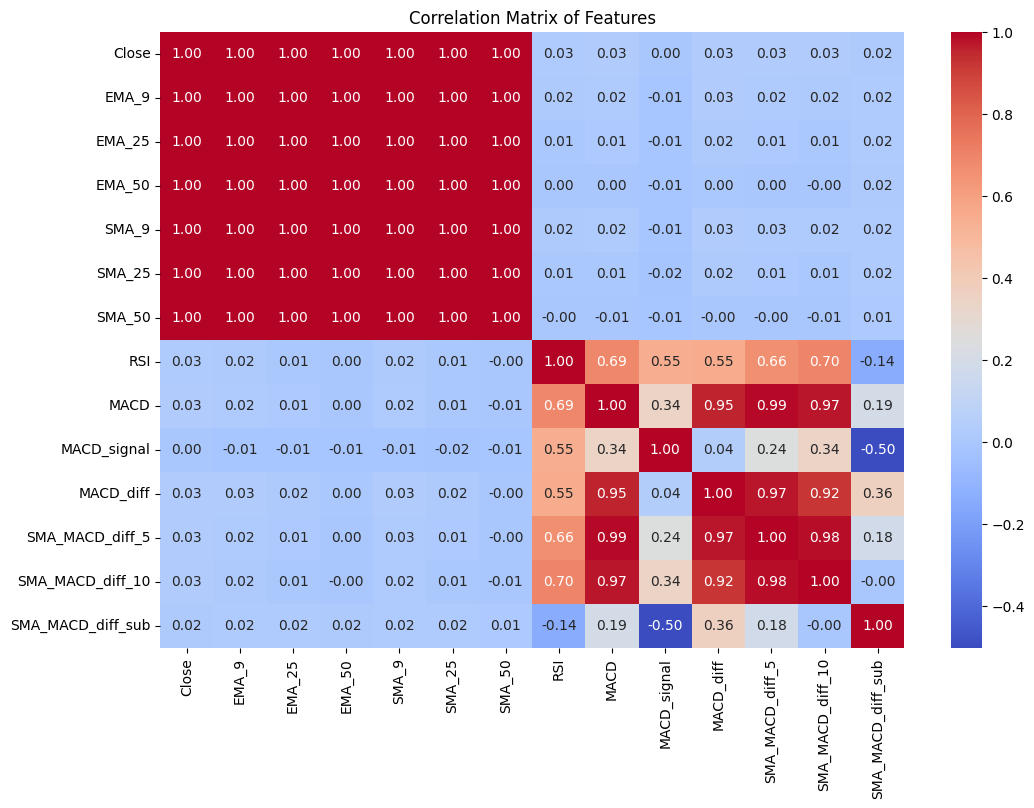

In [118]:
# 4. Kiểm tra tương quan
features_corr= [
    'Close', 
    'EMA_9', 'EMA_25', 'EMA_50',
    'SMA_9', 'SMA_25', 'SMA_50',
    'RSI',
    'MACD', 'MACD_signal', 'MACD_diff',
    'SMA_MACD_diff_5', 'SMA_MACD_diff_10', 'SMA_MACD_diff_sub'
]

correlation_matrix = df[features_corr].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Features')
plt.show()

CHIA DỮ LIỆU 70% TRAIN, 20% VALIDATION, 10% TEST

In [119]:
features = [
    'MACD_diff',
    'SMA_MACD_diff_sub'
]
X = df[features]
y = df[Y_TYPE]

# Chia dữ liệu: 70% train, 20% val, 10% test
# Bước 1: Chia 10% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, shuffle=False
)

# Bước 2: Chia 90% còn lại thành 77.8% train và 22.2% validation 
# (tương đương 70% và 20% của toàn bộ dữ liệu)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2222, random_state=42, shuffle=False
)

# Over sampling
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_smote)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [120]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [121]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [122]:
# Đưa về Tensor và reshape về (samples, seq_len=1, features)
X_train_gru = torch.tensor(X_train_scaled, dtype=torch.float32).unsqueeze(1).to(device)
X_val_gru = torch.tensor(X_val_scaled, dtype=torch.float32).unsqueeze(1).to(device)
X_test_gru = torch.tensor(X_test_scaled, dtype=torch.float32).unsqueeze(1).to(device)

# Chuyển nhãn (labels) về dạng Tensor và đưa lên device
y_train_gru = torch.tensor(y_train_smote.values, dtype=torch.float32).to(device)
y_val_gru = torch.tensor(y_val.values, dtype=torch.float32).to(device)
y_test_gru = torch.tensor(y_test.values, dtype=torch.float32).to(device)

# Dataloader
train_dataset = TensorDataset(X_train_gru, y_train_gru)
val_dataset = TensorDataset(X_val_gru, y_val_gru)

# Tạo DataLoader để load dữ liệu theo batch, giúp huấn luyện hiệu quả hơn
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128)

In [123]:
class GRUModel(nn.Module):
    def __init__(self, input_size):
        super(GRUModel, self).__init__()
        self.gru = nn.GRU(input_size=input_size, hidden_size=64, batch_first=True)
        self.dropout1 = nn.Dropout(0.3)
        self.fc1 = nn.Linear(64, 32)
        self.relu = nn.ReLU()
        self.dropout2 = nn.Dropout(0.3)
        self.output = nn.Linear(32, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        _, h = self.gru(x)  # h: (1, batch, hidden)
        x = self.dropout1(h[-1])
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout2(x)
        x = self.output(x)
        return self.sigmoid(x)

In [124]:
model_gru = GRUModel(input_size=X_train_gru.shape[2]).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model_gru.parameters(), lr=0.001)

best_val_loss = float('inf')
patience = 5
counter = 0

for epoch in range(100):
    model_gru.train()
    train_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model_gru(X_batch).view(-1)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation
    model_gru.eval()
    val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model_gru(X_batch).view(-1)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item()

    # Corrected print statement
    print(f"Epoch {epoch+1}, Train Loss: {train_loss/len(train_loader):.4f}, Val Loss: {val_loss/len(val_loader):.4f}")
    
    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model_gru.state_dict(), "best_gru_model.pth")
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping!")
            break

# Load mô hình tốt nhất
model_gru.load_state_dict(torch.load("best_gru_model.pth"))

Epoch 1, Train Loss: 0.5418, Val Loss: 0.5004
Epoch 2, Train Loss: 0.5256, Val Loss: 0.5004
Epoch 3, Train Loss: 0.5221, Val Loss: 0.4979
Epoch 4, Train Loss: 0.5214, Val Loss: 0.4971
Epoch 5, Train Loss: 0.5203, Val Loss: 0.4932
Epoch 6, Train Loss: 0.5200, Val Loss: 0.4837
Epoch 7, Train Loss: 0.5202, Val Loss: 0.4960
Epoch 8, Train Loss: 0.5194, Val Loss: 0.4994
Epoch 9, Train Loss: 0.5197, Val Loss: 0.4922
Epoch 10, Train Loss: 0.5194, Val Loss: 0.4935
Epoch 11, Train Loss: 0.5192, Val Loss: 0.4842
Early stopping!


C:\Users\ai1\AppData\Local\Temp\ipykernel_92140\3177770157.py:44: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_gru.load_state_dict(torch.load("best_gru_model.pth"))


<All keys matched successfully>

In [125]:
model_gru.eval()
with torch.no_grad():
    y_pred_gru = (model_gru(X_test_gru).squeeze().cpu().numpy() > 0.5).astype(int)

# Đảm bảo y_test là numpy array
y_test_gru = y_test_gru.cpu().numpy() if isinstance(y_test_gru, torch.Tensor) else y_test_gru

# In độ chính xác
acc = accuracy_score(y_test_gru, y_pred_gru) * 100
print(f"Độ chính xác của mô hình GRU: {acc:.2f}%")

# Tạo classification report dạng dict
report = classification_report(y_test_gru, y_pred_gru, output_dict=True)

# Hàm định dạng phần trăm (giữ dấu .)
def format_percent(value):
    return f"{value * 100:.2f}%"

# In report dạng phần trăm
print("\nBáo cáo phân loại (%):")
print(f"{'Label':<12} {'Precision':>10} {'Recall':>10} {'F1-score':>10} {'Support':>10}")
for label, metrics in report.items():
    if isinstance(metrics, dict):
        print(f"{label:<12} {format_percent(metrics['precision']):>10} {format_percent(metrics['recall']):>10} {format_percent(metrics['f1-score']):>10} {int(metrics['support']):>10}")
    elif label == "accuracy":
        print(f"{label:<12} {'-':>10} {'-':>10} {format_percent(metrics):>10} {int(report['macro avg']['support']):>10}")

Độ chính xác của mô hình GRU: 80.66%

Báo cáo phân loại (%):
Label         Precision     Recall   F1-score    Support
0.0              90.63%     84.06%     87.23%      18682
1.0              53.85%     68.16%     60.17%       5097
accuracy              -          -     80.66%      23779
macro avg        72.24%     76.11%     73.70%      23779
weighted avg     82.75%     80.66%     81.43%      23779


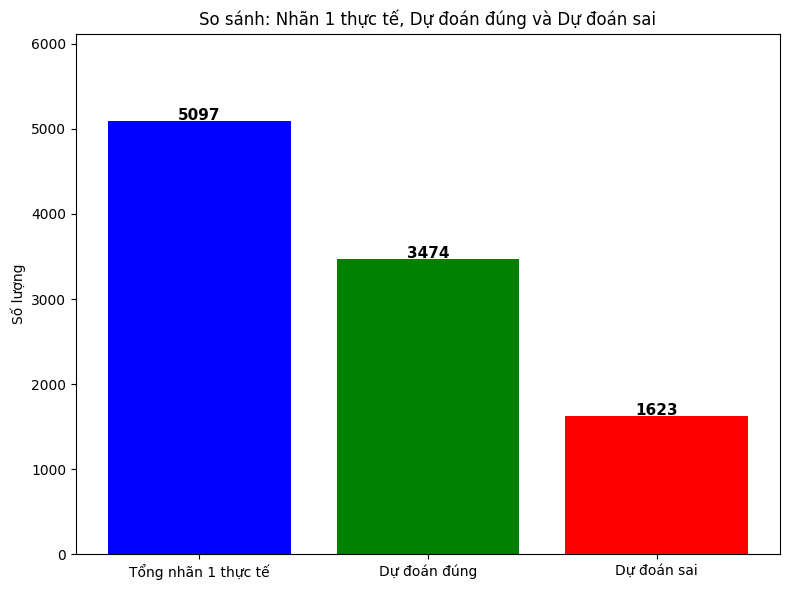

In [126]:
# Tạo confusion matrix
cm = confusion_matrix(y_test_gru, y_pred_gru)
tn, fp, fn, tp = cm.ravel()

# Tính các giá trị
total_label_1 = tp + fn            # Nhãn 1 thực tế
correct_predictions = tp     # Dự đoán đúng (TP + TN)
wrong_predictions = fn       # Dự đoán sai (FP + FN)

# Dữ liệu cho biểu đồ
labels = ['Tổng nhãn 1 thực tế', 'Dự đoán đúng', 'Dự đoán sai']
values = [total_label_1, correct_predictions, wrong_predictions]
colors = ['blue', 'green', 'red']

# Vẽ biểu đồ
plt.figure(figsize=(8, 6))
bars = plt.bar(labels, values, color=colors)

# Gắn giá trị lên đầu cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 10, f'{height}', ha='center', fontsize=11, fontweight='bold')

plt.title('So sánh: Nhãn 1 thực tế, Dự đoán đúng và Dự đoán sai')
plt.ylabel('Số lượng')
plt.ylim(0, max(values) * 1.2)
plt.tight_layout()
plt.show()

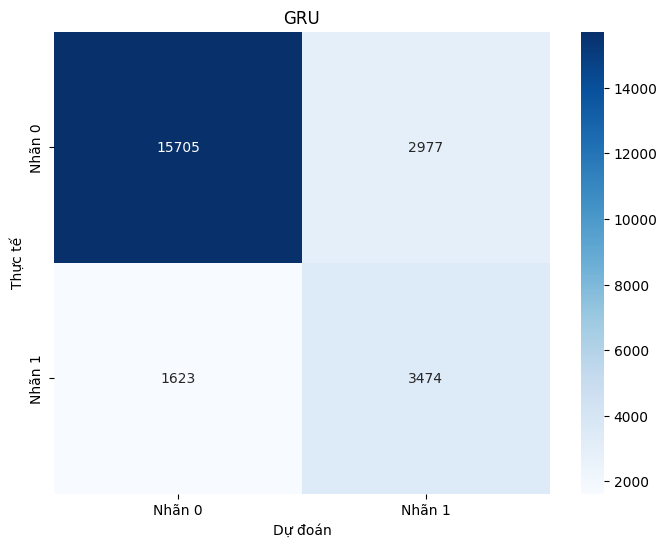

In [127]:
# Vẽ heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Nhãn 0', 'Nhãn 1'], yticklabels=['Nhãn 0', 'Nhãn 1'])
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title('GRU')
plt.show()

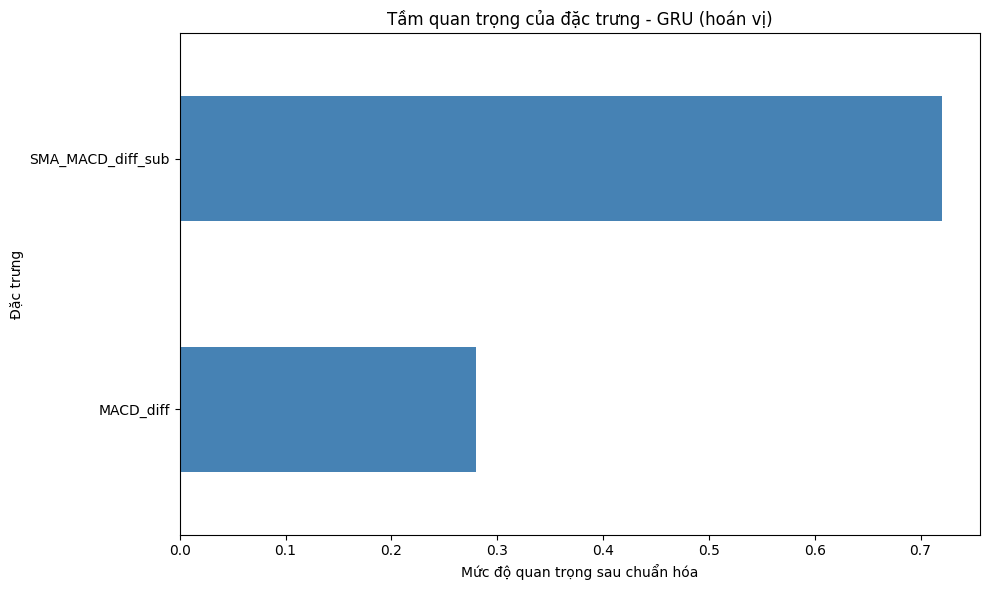

In [128]:
def permutation_importance_gru(model, X_val, y_val, features, device, metric=mean_absolute_error):
    model.eval()
    
    # Nếu y_val là Series → chuyển sang tensor
    if isinstance(y_val, pd.Series):
        y_val = torch.tensor(y_val.values, dtype=torch.float32).to(device)
    
    X_val_copy = X_val.clone()
    baseline_preds = model(X_val_copy).cpu().detach().numpy()
    baseline_score = metric(y_val.cpu().numpy(), baseline_preds)
    
    importances = []
    for col_idx in range(X_val.shape[2]):
        X_permuted = X_val.clone()
        permuted_values = X_permuted[:, :, col_idx].cpu().numpy().copy()
        np.random.shuffle(permuted_values)
        X_permuted[:, :, col_idx] = torch.tensor(permuted_values, dtype=torch.float32).to(device)
        permuted_preds = model(X_permuted).cpu().detach().numpy()
        permuted_score = metric(y_val.cpu().numpy(), permuted_preds)
        importance = abs(permuted_score - baseline_score)
        importances.append(importance)
    
    importances = np.array(importances)
    return importances, baseline_score

importances, baseline_score = permutation_importance_gru(
    model_gru, X_val_gru, y_val_gru, features, device
)

gru_importance_raw = pd.Series(importances, index=features)
gru_importance = gru_importance_raw / gru_importance_raw.sum()
gru_importance = gru_importance.sort_values()

plt.figure(figsize=(10, 6))
gru_importance.plot(kind='barh', color='steelblue')
plt.xlabel('Mức độ quan trọng sau chuẩn hóa')
plt.ylabel('Đặc trưng')
plt.title('Tầm quan trọng của đặc trưng - GRU (hoán vị)')
plt.tight_layout()
plt.show()